In [23]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Simulation data of exctinction spectra for different AR

In [24]:
path_exp = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'
path_simu = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR'

simu_shape = 'round'
sample_name = 'Silice thick'

In [25]:
root_simu = '\\'.join((path_simu, sample_name, simu_shape, 'Treated_SPR'))
fname_data_simu = 'Treated_simulations'

#kernel = 'thin_plate_spline'
Simu_SPR, Lda_RBF, E_RBF, W_RBF, Aire_RBF, points = get_SPR_simu_data_and_interpolate(root_simu, fname_data_simu, kernel='linear')

#h_1D = 25


H_lisse = np.linspace(0, 55, 200)
D_lisse = np.linspace(0, 180, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))

C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:46: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3, 3, 4], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:46: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3, 3, 4], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:46: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3, 3, 4], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:46: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3, 3, 4], colors='black', alpha=0.6)


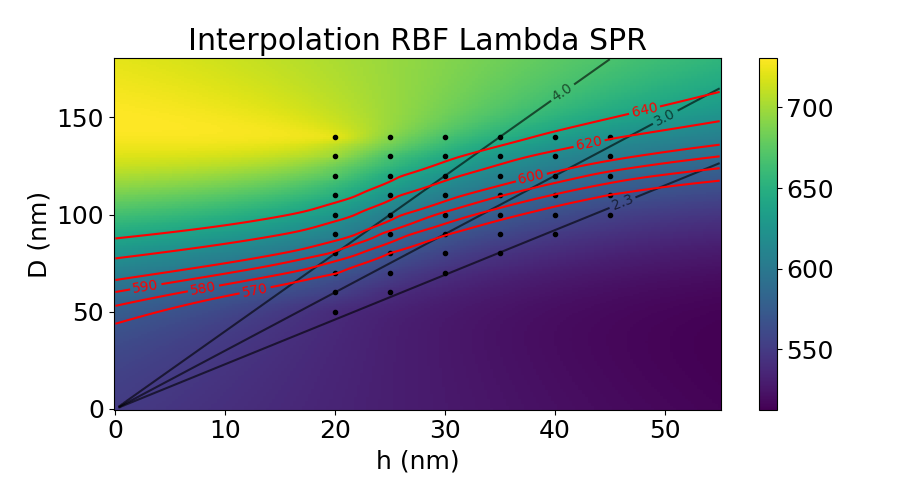

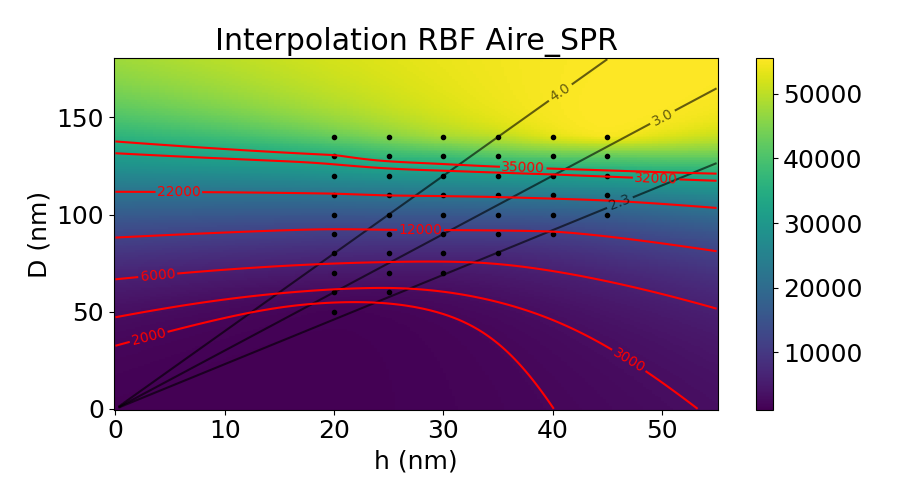

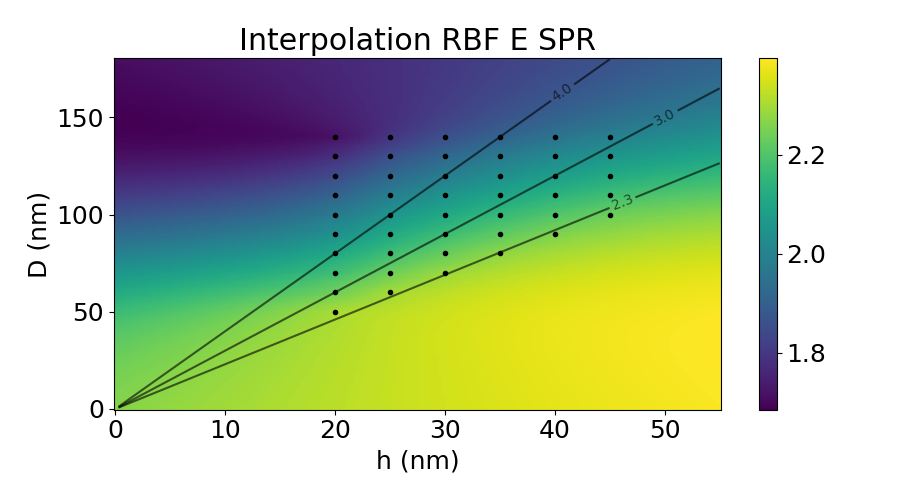

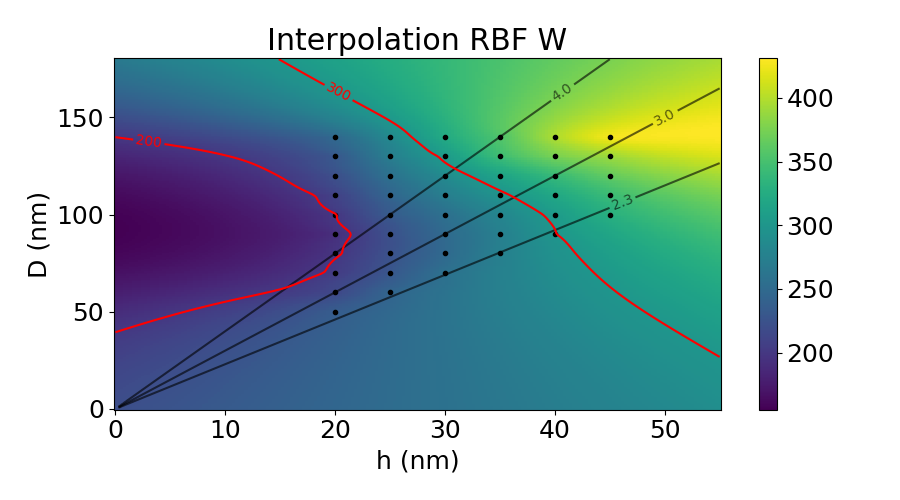

In [26]:
os.chdir(root_simu)

plot_func_interp(Lda_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points, title='Lambda SPR', contour_specif=[570, 580, 590,  600, 620, 640])
plt.savefig('Lambda SPR 2D interp.pdf')
plt.savefig('Lambda SPR 2D interp.png')
plot_func_interp(Aire_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points, title='Aire_SPR', contour_specif=[1000, 2000, 3000,6000, 12000,22000, 32000, 35000])
plt.savefig('Area SPR 2D interp.pdf')
plt.savefig('Area SPR 2D interp.png')
plot_func_interp(E_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points, title='E SPR')
plot_func_interp(W_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points, title='W', contour_specif=[50, 100, 150, 200, 300])

## Get experimental data of ND

In [27]:
dir_root_ND = '\\'.join((path_exp,sample_name, r'AR_estimation\ND_measurements'))
fname_Exp = 'Nd_measurements_data.dat'
Exp_data = get_ND_measures(dir_root_ND, fname_Exp)


# for key in Exp_data :
#     print('----------------------------------------------')
#     for kkey in Exp_data[key] :
#         print(kkey, '///',  Exp_data[key][kkey])


## Estimate the AR of experimental data

In [28]:
#d_guess, h_guess, h_1D = 27, 71, 25 # for Sapphire
#d_guess, h_guess, h_1D = 101, 31, 21 # for Silica thick - e 30 nm
d_guess, h_guess, h_1D = 71, 71, 21 # for Silica thick
#d_guess, h_guess, h_1D = 101, 19, 19 # for Silica membrane

## Interpolation 1D with Area of SPR
AR_estimation_1D_Aire_SPR(Exp_data, Aire_RBF, h=h_1D)
AR_estimation_1D_Lda_SPR(Exp_data, Lda_RBF, h=h_1D)

## Interpolation 2D with Area and position of SPR
AR_estimation_2D(Exp_data, Lda_RBF, Aire_RBF, d_guess=d_guess, h_guess=h_guess)


# Estimate the term Gamma_surf
Gamma_surf_estimation(Exp_data, W_RBF)

Erreur de convergence 2D sur : 4.5 zone-1 D4 - (Lda_SPR, Aire_SPR) = (650.0, 33200.0)
Erreur de convergence 2D sur : 4.5 zone-1 D6 - (Lda_SPR, Aire_SPR) = (640.0, 32200.0)
Erreur de convergence 2D sur : 4.5 zone 2 D1 - (Lda_SPR, Aire_SPR) = (667.0, 29800.0)


## Try to find the 2D AR by hand when the numerical convergence fails but the result exists

## Add handmade interpolation to treated Data

In [29]:
fname = 'AR interpolation by hand - ' + simu_shape  +'.dat'

try :
    ND_handmade = get_handmade_interpolation(dir_root_ND, fname)
    add_handmade_interpolation_to_treated_data(Exp_data,ND_handmade)
except :
    print('No interpolations added')
    pass

value added for 4.5 zone-1 D4
value added for 4.5 zone-1 D6
value added for 4.5 zone 2 D1


C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:65: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots( figsize=(9,5))


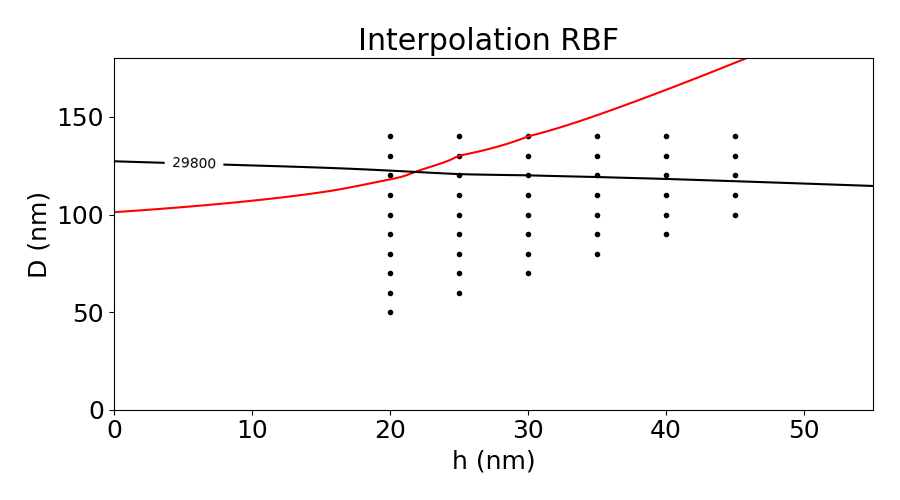

In [30]:
lambda_spr, airea_spr = (667.0, 29800)

plot_2_level_lines(Lda_RBF, Aire_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points,  contour_specif_lda=[lambda_spr], contour_specif_Area = [airea_spr],title = '')

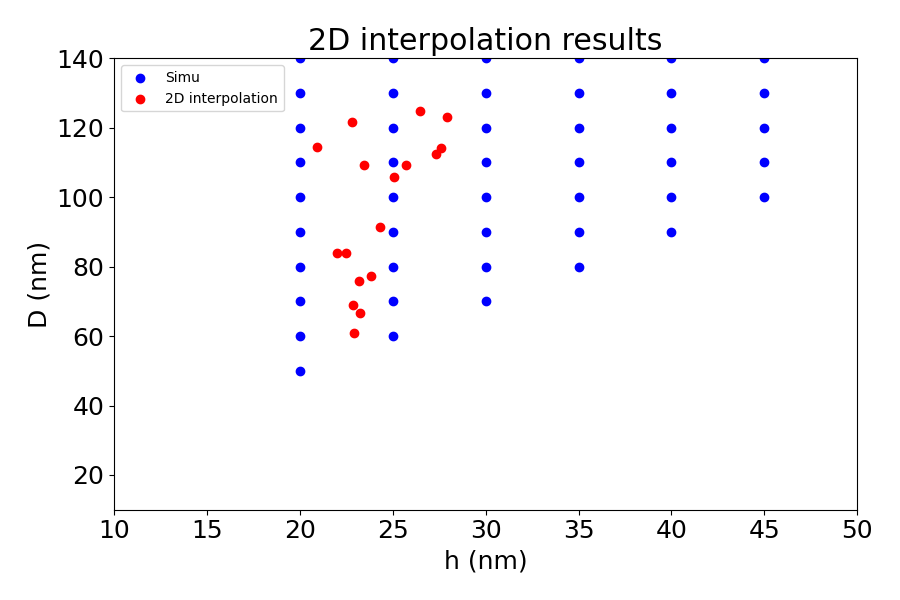

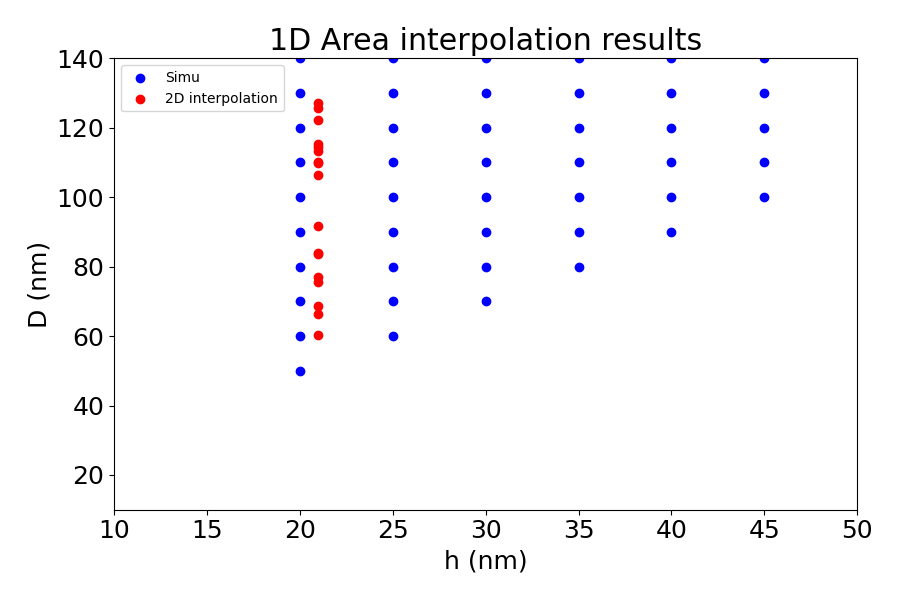

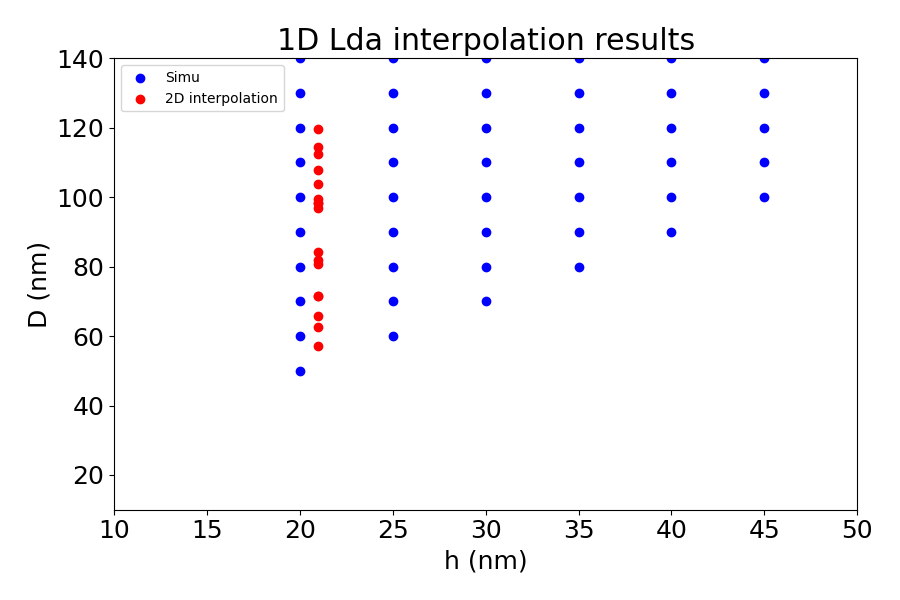

In [31]:
fig, ax = plt.subplots(figsize = (9,6))
print_2D_AR_interpolations(Exp_data, points, ax)
ax.set_title('2D interpolation results')

plt.legend(fontsize=10)
plt.tight_layout()

fig, ax = plt.subplots(figsize = (9,6))
print_1D_Area_AR_interpolations(Exp_data, points, ax)
ax.set_title('1D Area interpolation results')

plt.legend(fontsize=10)
plt.tight_layout()

fig, ax = plt.subplots(figsize = (9,6))
print_1D_Lda_AR_interpolations(Exp_data, points, ax)
ax.set_title('1D Lda interpolation results')

plt.legend(fontsize=10)
plt.tight_layout()

In [32]:
print(W_RBF([[23.85, 92.1]]))

[216.70472255]


## Saving Data

In [ ]:
if 0 :
    
    dir_save_data = path_exp + sample_name + r'\AR_estimation\ND_measurements_AR_treated'
    dir_save_data = '\\'.join((path_exp,sample_name, r'AR_estimation\ND_measurements_AR_treated'))

    fname_1D = 'AR_interpolation_results - ' + simu_shape + ' - h ' + str(h_1D) + 'nm' + '.csv'
    save_interpolation_to_csv(Exp_data, dir_save_data, fname_1D)

    fname_pickle = 'Treated_data - ' + simu_shape + ' - h ' + str(h_1D) + 'nm'
    save_interpolation_to_data_dic(Exp_data, dir_save_data, fname_pickle)